# Cross-Dataset Comparison: Does SHAP-Guided SMOTE Generalise?
This notebook reads the metrics saved by the four dataset notebooks (`results/<dataset>/metrics/`) and compares all
methods across Breast Cancer, Credit Card Fraud, Stroke and NSL-KDD. Every number is a cross-validation mean
(2 × 5 folds) unless labelled as hold-out test. Run notebooks 01-04 first.

In [1]:
import sys, warnings
from pathlib import Path

# Locate the repository root (the folder that contains src/), wherever the notebook is run from
REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "experiment").is_dir())
sys.path.insert(0, str(REPO_ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src.experiment import config as C
from src.experiment import data as D, preprocessing as P, runner as R, inspection as I
from src.experiment import plots as PL, outputs as O, summary as S

%matplotlib inline
PL.set_style()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

PLOTS = O.results_dirs("cross_dataset")["plots"]
results = S.load_all_results()
print('loaded:', list(results))

loaded: ['breast_cancer', 'credit_card', 'stroke', 'nsl_kdd']


## 1. Datasets

In [2]:
rows = []
for slug in results:
    df_, spec_ = D.load_dataset(slug)
    rows.append(D.overview(df_, spec_).reset_index())
overview_all = pd.concat(rows).set_index("Dataset")
display(overview_all)

,Domain,Rows,Numeric features,Categorical features,Majority (0),Minority (1),Minority %,Imbalance ratio,Minority:majority
Dataset,,,,,,,,,
Breast Cancer Wisconsin (Diagnostic),Medical diagnosis,396,30,0,357,39,9.85%,9.2 : 1,1 : 9.2
Credit Card Fraud Detection (ULB),Financial fraud,275663,29,0,275190,473,0.17%,581.8 : 1,1 : 581.8
Stroke Prediction,Clinical risk prediction,5110,5,5,4861,249,4.87%,19.5 : 1,1 : 19.5
NSL-KDD Network Intrusion (KDDTrain+),Network security,73199,37,3,67343,5856,8.00%,11.5 : 1,1 : 11.5


## 2. Cross-dataset performance tables (CV means)

In [3]:
for metric in ["pr_auc", "f1", "recall", "precision", "roc_auc"]:
    display(Markdown(f"**{R.METRIC_LABELS[metric]}**"))
    display(S.cross_cv_means(results, metric).style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))

**PR-AUC**

**F1**

**Recall**

**Precision**

**ROC-AUC**

## 3. F1, PR-AUC and recall across datasets

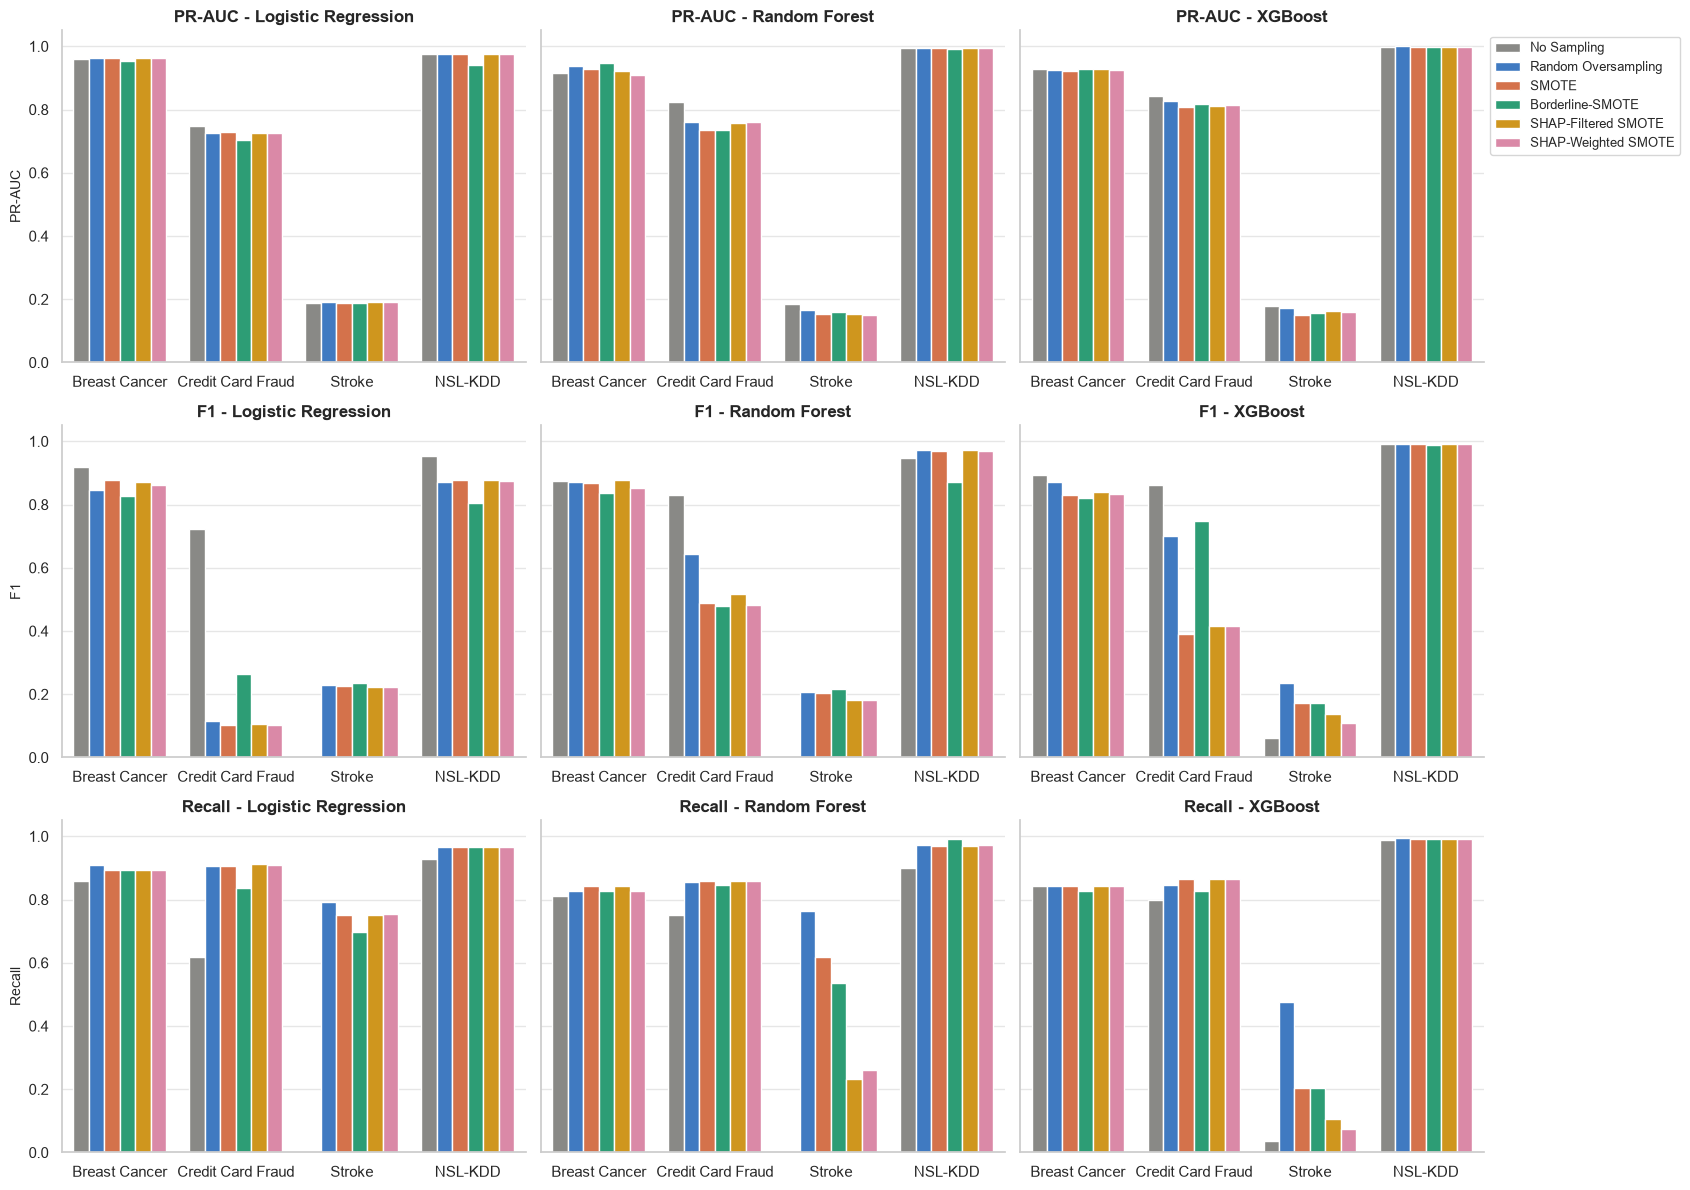

In [4]:
import seaborn as sns
fig, axes = plt.subplots(3, 3, figsize=(17, 12), sharey="row")
for r, metric in enumerate(["pr_auc", "f1", "recall"]):
    t = S.cross_cv_means(results, metric).reset_index().melt(id_vars=["dataset", "model"], var_name="method", value_name=metric)
    for c, model in enumerate(C.MODEL_ORDER):
        ax = axes[r, c]
        sns.barplot(data=t[t.model == model], x="dataset", y=metric, hue="method", hue_order=C.METHOD_ORDER,
                    palette=C.METHOD_COLORS, ax=ax)
        ax.set(title=f"{R.METRIC_LABELS[metric]} - {model}", xlabel="", ylabel=R.METRIC_LABELS[metric], ylim=(0, 1.05))
        if (r, c) != (0, 2):
            ax.get_legend().remove()
        else:
            ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); fig.savefig(PLOTS / "cross_dataset_f1_prauc_recall.png", bbox_inches="tight"); plt.show()

## 4. Relative improvement of SHAP-guided SMOTE over conventional SMOTE

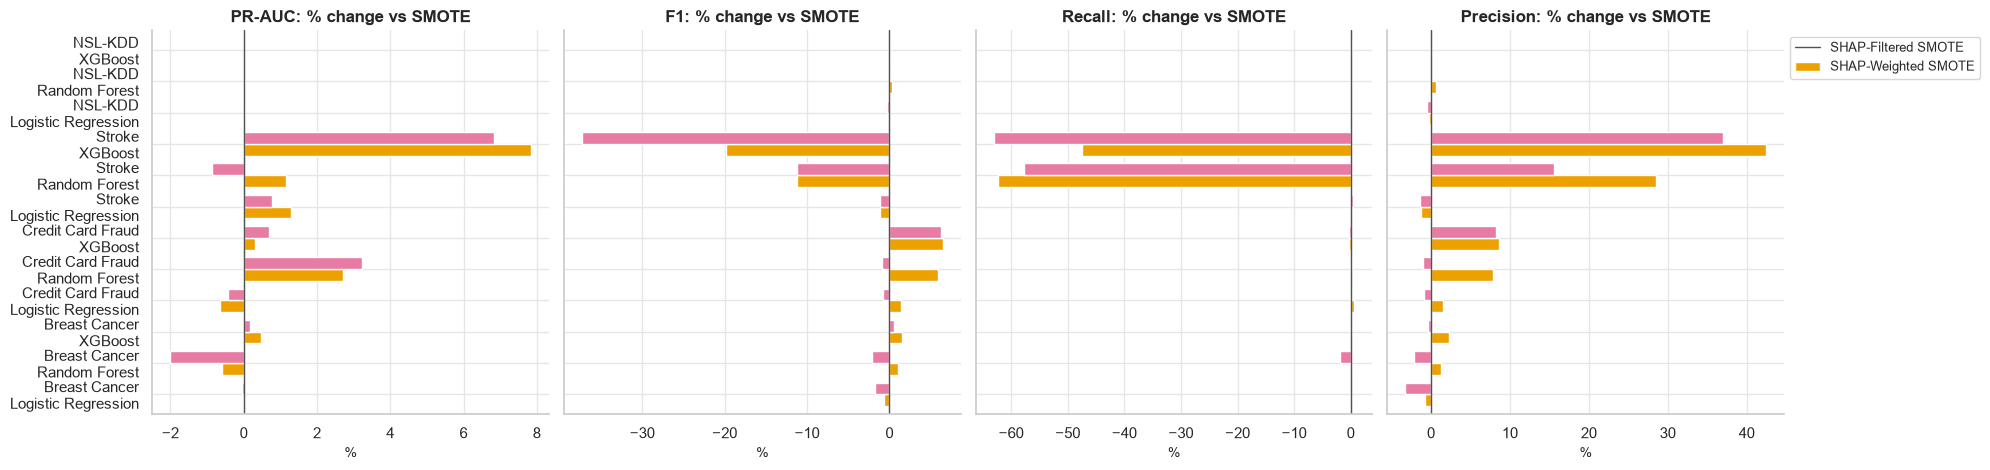

In [5]:
rel = pd.concat({R.METRIC_LABELS[m]: S.relative_improvement(results, m) for m in ["pr_auc", "f1", "recall", "precision"]}, axis=1)
display(rel.style.format("{:+.1f}%").background_gradient(cmap="RdBu", vmin=-20, vmax=20, axis=None))
fig, axes = plt.subplots(1, 4, figsize=(20, 4.8), sharey=True)
for ax, metric in zip(axes, ["pr_auc", "f1", "recall", "precision"]):
    t = S.relative_improvement(results, metric)
    t.index = [f"{d}\n{m}" for d, m in t.index]
    t.plot.barh(ax=ax, color=[C.METHOD_COLORS[m] for m in t.columns], width=0.75, legend=False)
    ax.axvline(0, color="#52514e", linewidth=1)
    ax.set(title=f"{R.METRIC_LABELS[metric]}: % change vs SMOTE", xlabel="%")
axes[-1].legend(t.columns, loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); fig.savefig(PLOTS / "relative_improvement_vs_smote.png", bbox_inches="tight"); plt.show()

## 5. Best method per dataset and model

In [6]:
for metric in ["pr_auc", "f1"]:
    display(Markdown(f"**Best method by {R.METRIC_LABELS[metric]}**"))
    display(S.best_methods(results, metric))
    display(S.best_methods(results, metric)["best method"].value_counts().to_frame("wins (dataset x model blocks)"))

**Best method by PR-AUC**

best method  best mean  SMOTE  No Sampling
dataset           model                                                                  
Breast Cancer     Logistic Regression  Random Oversampling     0.9625 0.9624       0.9612
                  Random Forest           Borderline-SMOTE     0.9462 0.9274       0.9156
                  XGBoost                 Borderline-SMOTE     0.9291 0.9223       0.9271
Credit Card Fraud Logistic Regression          No Sampling     0.7485 0.7289       0.7485
                  Random Forest                No Sampling     0.8241 0.7361       0.8241
                  XGBoost                      No Sampling     0.8422 0.8084       0.8422
Stroke            Logistic Regression  SHAP-Filtered SMOTE     0.1920 0.1896       0.1889
                  Random Forest                No Sampling     0.1835 0.1528       0.1835
                  XGBoost                      No Sampling     0.1786 0.1505       0.1786
NSL-KDD           Logistic Regression  SHAP-Weighted SMOTE     0.9764 0.9759       0.9761
                  Random Forest        SHAP-Filtered SMOTE     0.9952 0.9949       0.9936
                  XGBoost              Random Oversampling     0.9993 0.9991       0.9992

,wins (dataset x model blocks)
best method,
No Sampling,5
Random Oversampling,2
Borderline-SMOTE,2
SHAP-Filtered SMOTE,2
SHAP-Weighted SMOTE,1


**Best method by F1**

best method  best mean  SMOTE  No Sampling
dataset           model                                                                  
Breast Cancer     Logistic Regression          No Sampling     0.9186 0.8780       0.9186
                  Random Forest        SHAP-Filtered SMOTE     0.8783 0.8692       0.8729
                  XGBoost                      No Sampling     0.8925 0.8287       0.8925
Credit Card Fraud Logistic Regression          No Sampling     0.7238 0.1034       0.7238
                  Random Forest                No Sampling     0.8305 0.4881       0.8305
                  XGBoost                      No Sampling     0.8618 0.3918       0.8618
Stroke            Logistic Regression     Borderline-SMOTE     0.2359 0.2259       0.0000
                  Random Forest           Borderline-SMOTE     0.2154 0.2048       0.0000
                  XGBoost              Random Oversampling     0.2351 0.1732       0.0607
NSL-KDD           Logistic Regression          No Sampling     0.9544 0.8769       0.9544
                  Random Forest        Random Oversampling     0.9738 0.9686       0.9463
                  XGBoost                      No Sampling     0.9926 0.9918       0.9926

,wins (dataset x model blocks)
best method,
No Sampling,7
Borderline-SMOTE,2
Random Oversampling,2
SHAP-Filtered SMOTE,1


## 6. Overall consistency: average ranks, Friedman test and paired tests vs SMOTE

PR-AUC     Friedman chi2 =  10.78, p = 0.0560  (12 dataset x model blocks, 6 methods)
F1         Friedman chi2 =   9.05, p = 0.1072  (12 dataset x model blocks, 6 methods)
Recall     Friedman chi2 =  29.64, p = 0.0000  (12 dataset x model blocks, 6 methods)
Precision  Friedman chi2 =  17.38, p = 0.0038  (12 dataset x model blocks, 6 methods)


,PR-AUC,F1,Recall,Precision
method,,,,
Borderline-SMOTE,4.42,4.25,4.17,4.50
No Sampling,2.75,2.67,5.75,1.83
Random Oversampling,2.50,2.75,2.33,3.33
SHAP-Filtered SMOTE,3.29,3.25,3.17,3.00
SHAP-Weighted SMOTE,3.75,4.33,2.83,4.42
SMOTE,4.29,3.75,2.75,3.92


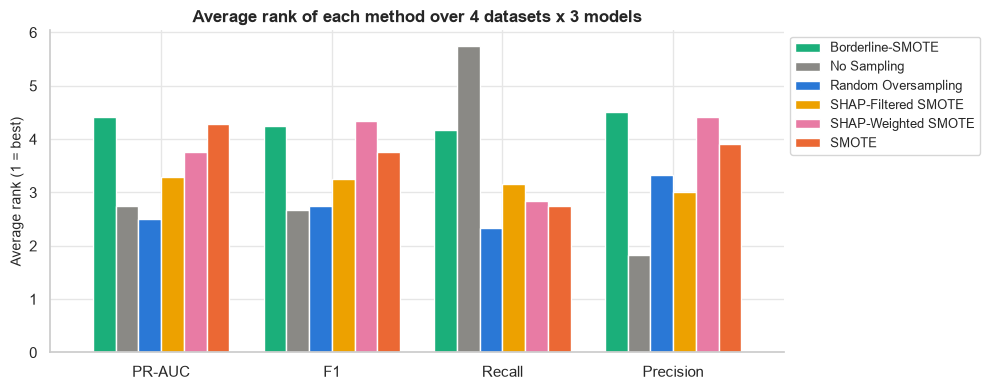

**Fold-paired Wilcoxon tests of each proposed method vs SMOTE, counted over the 12 dataset x model blocks**

outcome                        no significant difference  significantly better  significantly worse
method              metric                                                                         
SHAP-Filtered SMOTE F1                                11                     1                    0
                    PR-AUC                            11                     1                    0
                    Precision                         10                     2                    0
                    Recall                            10                     0                    2
SHAP-Weighted SMOTE F1                                 9                     1                    2
                    PR-AUC                            12                     0                    0
                    Precision                          9                     2                    1
                    Recall                             9                     1                    2

In [7]:
rank_tables = {}
for metric in ["pr_auc", "f1", "recall", "precision"]:
    ranks, stat, p = S.average_ranks(results, metric)
    rank_tables[R.METRIC_LABELS[metric]] = ranks
    print(f"{R.METRIC_LABELS[metric]:<10} Friedman chi2 = {stat:6.2f}, p = {p:.4f}  (12 dataset x model blocks, 6 methods)")
ranks_df = pd.DataFrame(rank_tables)
display(ranks_df.style.format("{:.2f}").highlight_min(axis=0, props="font-weight: bold"))
fig, ax = plt.subplots(figsize=(10, 4))
ranks_df.T.plot.bar(ax=ax, color=[C.METHOD_COLORS[m] for m in ranks_df.index], width=0.8)
ax.set(ylabel="Average rank (1 = best)", xlabel="", title="Average rank of each method over 4 datasets x 3 models")
ax.tick_params(axis="x", rotation=0); ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0))
fig.tight_layout(); fig.savefig(PLOTS / "average_ranks.png", bbox_inches="tight"); plt.show()
display(Markdown("**Fold-paired Wilcoxon tests of each proposed method vs SMOTE, counted over the 12 dataset x model blocks**"))
display(S.significance_overview(results))

In [8]:
display(Markdown("**Synthetic-sample quality across datasets**"))
q = pd.concat({S.DATASET_TITLES[s]: r["quality"].set_index("method") for s, r in results.items()})
display(q.reindex(columns=["synthetic_rows", "majority_share_in_5nn", "mean_wasserstein_distance", "correlation_matrix_similarity",
                           "parents_SHAP_cosine_mean", "detectability_auc_all", "detectability_auc_numeric",
                           "fractional_onehot_cols_per_row"]))
display(Markdown("**Hold-out test PR-AUC (single split, for reference)**"))
test_pr = pd.concat({S.DATASET_TITLES[s]: r["test"].pivot(index="model", columns="method", values="pr_auc")[C.METHOD_ORDER]
                     for s, r in results.items()})
display(test_pr.style.format("{:.3f}").highlight_max(axis=1, props="font-weight: bold"))
rt = pd.concat({S.DATASET_TITLES[s]: r["sampling"].groupby("method")["sampling_seconds"].mean().reindex(C.METHOD_ORDER)
                for s, r in results.items()}, axis=1)
display(Markdown("**Mean oversampling time per CV fold (seconds; SHAP methods include the preliminary model and SHAP)**"))
display(rt)

**Synthetic-sample quality across datasets**

synthetic_rows  majority_share_in_5nn  mean_wasserstein_distance  correlation_matrix_similarity  parents_SHAP_cosine_mean  detectability_auc_all  \
                  method                                                                                                                                                                        
Breast Cancer     Real minority (reference)               0                 0.2207                        NaN                            NaN                       NaN                    NaN   
                  Random Oversampling                   239                 0.1632                     0.0595                         0.9961                       NaN                    NaN   
                  SMOTE                                 239                 0.1213                     0.1864                         0.9821                    0.8353                 0.5258   
                  Borderline-SMOTE                      239                 0.3615                     0.6074                         0.7080                    0.7009                 0.7556   
                  SHAP-Filtered SMOTE                   239                 0.1238                     0.1748                         0.9788                    0.8473                 0.5172   
                  SHAP-Weighted SMOTE                   239                 0.1280                     0.1794                         0.9843                    0.8586                 0.5362   
Credit Card Fraud Real minority (reference)               0                 0.2507                        NaN                            NaN                       NaN                    NaN   
                  Random Oversampling                206037                 0.1976                     0.0062                         1.0000                       NaN                    NaN   
                  SMOTE                              206037                 0.1772                     0.1237                         0.9971                    0.8965                 0.5619   
                  Borderline-SMOTE                   206037                 0.3496                     1.1780                         0.9278                    0.8593                 0.7844   
                  SHAP-Filtered SMOTE                206037                 0.1756                     0.1196                         0.9970                    0.9042                 0.5782   
                  SHAP-Weighted SMOTE                206037                 0.1867                     0.1199                         0.9969                    0.9122                 0.5755   
Stroke            Real minority (reference)               0                 0.8973                        NaN                            NaN                       NaN                    NaN   
                  Random Oversampling                  3458                 0.7193                     0.0074                         0.9958                       NaN                    NaN   
                  SMOTE                                3458                 0.6787                     0.0403                         0.9846                    0.7349                 0.8082   
                  Borderline-SMOTE                     3458                 0.6313                     0.0649                         0.9064                    0.8051                 0.7720   
                  SHAP-Filtered SMOTE                  3458                 0.6912                     0.0579                         0.9883                    0.8049                 0.9251   
                  SHAP-Weighted SMOTE                  3458                 0.6903                     0.0588                         0.9839                    0.8789                 0.9621   
NSL-KDD           Real minority (reference)               0                 0.0214                        NaN                            NaN                       NaN                   

**Hold-out test PR-AUC (single split, for reference)**

**Mean oversampling time per CV fold (seconds; SHAP methods include the preliminary model and SHAP)**

,Breast Cancer,Credit Card Fraud,Stroke,NSL-KDD
method,,,,
No Sampling,0.0062,0.0516,0.0075,0.0517
Random Oversampling,0.0083,0.5606,0.0122,0.2986
SMOTE,0.0432,7.0768,0.1620,1.7751
Borderline-SMOTE,0.0553,7.5044,0.1670,2.5907
SHAP-Filtered SMOTE,0.3989,20.7420,2.0055,9.1281
SHAP-Weighted SMOTE,0.3080,20.8540,1.9041,10.8620


## 7. Interpretation

**Does SHAP-guided SMOTE generalise?** Not as a consistent improvement. Across 4 datasets × 3 models (12 blocks),
the proposed methods beat conventional SMOTE in some settings, tie in most, and fail badly in one.

| Dataset | SHAP-guided vs SMOTE (CV, fold-paired Wilcoxon) |
|---|---|
| Breast Cancer (9.2:1) | Tie. All differences within ±0.02; none significant. |
| Credit Card Fraud (581.8:1) | **Better with tree models.** XGBoost F1 +0.025 and precision +0.02 for both SHAP methods (p ≤ 0.014); Random Forest PR-AUC +0.020 for SHAP-Filtered (p = 0.037). Recall unchanged. |
| Stroke (19.5:1) | **Worse with tree models.** Recall −47% to −63% relative (p = 0.002 in all four cases, every fold). PR-AUC unchanged. Caused by interpolated one-hot categories (see below). |
| NSL-KDD (11.5:1) | Tie in practice. Differences ≤ 0.007; two tiny significant effects in opposite directions. |

**Which method performed best overall?** No method dominates. The Friedman test over the 12 blocks does not find a
significant difference between the six methods on PR-AUC (p = 0.056) or F1 (p = 0.107). It does on recall
(p < 0.001) and precision (p = 0.004), which reflects the basic trade-off: oversampling buys recall and
pays in precision. By average rank (1 = best):
* **PR-AUC:** Random Oversampling 2.50, No Sampling 2.75, **SHAP-Filtered 3.29**, **SHAP-Weighted 3.75**, SMOTE 4.29, Borderline-SMOTE 4.42.
* **F1:** No Sampling 2.67, Random Oversampling 2.75, **SHAP-Filtered 3.25**, SMOTE 3.75, Borderline-SMOTE 4.25, **SHAP-Weighted 4.33**.

**No Sampling** is the best single choice by F1 in 7 of 12 blocks and by PR-AUC in 5. On Credit Card Fraud, every
oversampler is far behind it (XGBoost F1 0.86 vs ≤ 0.75), because full 1:1 balancing is a poor operating point.

**Did SHAP-guided SMOTE improve minority-class detection, PR-AUC and F1?** Compared with SMOTE specifically:
* **SHAP-Filtered SMOTE** has a higher mean PR-AUC in 8 of 12 blocks, but only 1 of those is significant. It ranks
  above SMOTE on both PR-AUC and F1, and it is the more robust of the two proposed variants.
* **SHAP-Weighted SMOTE** has a higher mean PR-AUC in 7 of 12 blocks (none significant) and ranks *below* SMOTE on F1:
  it is significantly worse on F1 in 2 blocks and better in 1.
* Recall is never improved in a practically meaningful way. The one significant recall gain is +0.0015 on
  NSL-KDD. The gains that do appear come from **precision** (Credit Card trees: +8–9% relative).

**Did the synthetic samples preserve meaningful feature relationships?** On numeric features, about as well as
SMOTE. Correlation-structure similarity and KS pass rates match SMOTE on every dataset. The share of majority
rows among a synthetic row's 5 nearest real neighbours is within about 0.01 of SMOTE's. Numeric-only
detectability is within ±0.05 of SMOTE's: slightly higher on Breast Cancer and Credit Card (+0.01 to +0.02),
lower on Stroke and NSL-KDD (−0.03 to −0.05). SHAP guidance changes a large part of the neighbour graph (mean
Jaccard with SMOTE's neighbour sets 0.36–0.38 on Stroke, 0.50–0.56 on NSL-KDD and Credit Card, 0.61–0.69 on Breast
Cancer). On three datasets it pairs parents with more similar explanations; on NSL-KDD all methods are already at
about 0.98 SHAP cosine. The change in *which* rows get paired is substantial, but the change in the *resulting
numeric distribution* is small, which is why most downstream effects are small.

**Where did it fail?** On mixed numeric/categorical data. SHAP gives one-hot columns low weight, so SHAP-guided
neighbours more often come from different categories, and interpolation leaves 1.6× (Stroke) to 7× (NSL-KDD) more
fractional category indicators than SMOTE. On Stroke, a small minority with weak numeric signal, this made the
synthetic rows easy to recognise (detectability 0.93–0.96 vs 0.81) and tree models learned the artefact, losing
half their recall. On NSL-KDD, a large minority with strong signal, the same artefact was harmless. A
categorical-aware generation step (snapping one-hot groups, or SMOTE-NC-style handling) is the obvious fix.
It is outside this benchmark.

**Cost.** The SHAP step makes the proposed oversamplers 3–12× slower than SMOTE (for example 21 s vs 7 s per Credit
Card fold), even with the large-data SHAP row cap.

**Bottom line.** Under a leak-free protocol on four real datasets, SHAP-guided SMOTE is a *situational*
improvement over conventional SMOTE, not a general one. It helps the tree models on the extremely imbalanced,
all-numeric fraud data (mainly through precision), is neutral where SMOTE's neighbours are already good, and is
harmful on mixed-type data with a weak signal. SHAP-Filtered SMOTE is the safer of the two variants. Neither variant
changes the larger conclusion that the decision to oversample at all, and how far to balance, matters more than
which oversampler is used.